In [1]:
#Project Workflow

#1)Dataset collection
#2)Text preprocessing and cleaning
#3)Exploratory text analysis
#4)Tokenization and vocabulary creation
#)Sequence generation and padding
#6)N-gram language model development
#7)LSTM model development
#8)GRU model development
#9)Model evaluation and performance comparison
#10)Next-word prediction and Streamlit application development

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_dataset

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
#step-1 dataset collection

In [4]:
#dataset import

dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
print(dataset)

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})


In [6]:
#display sample text

for i in range(10):
    print(f"Record {i + 1}:")
    print(repr(dataset["train"][i]["text"]))
    print("-" * 60)

Record 1:
''
------------------------------------------------------------
Record 2:
' = Valkyria Chronicles III = \n'
------------------------------------------------------------
Record 3:
''
------------------------------------------------------------
Record 4:
' Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " . \n'
---------------------------

In [7]:
#Convert the splits into DataFrames

train_df = pd.DataFrame(dataset["train"])
validation_df = pd.DataFrame(dataset["validation"])
test_df = pd.DataFrame(dataset["test"])

print("Training DataFrame shape:", train_df.shape)
print("Validation DataFrame shape:", validation_df.shape)
print("Testing DataFrame shape:", test_df.shape)

Training DataFrame shape: (36718, 1)
Validation DataFrame shape: (3760, 1)
Testing DataFrame shape: (4358, 1)


In [8]:
#training data

train_df.head(10)

,text
0,
1,= Valkyria Chronicles III = \n
2,
3,Senjō no Valkyria 3 : Unrecorded Chronicles (...
4,"The game began development in 2010 , carrying..."
5,"It met with positive sales in Japan , and was..."
6,
7,= = Gameplay = = \n
8,
9,"As with previous Valkyira Chronicles games , ..."


In [9]:
#Check column names and data types

print("Columns:", train_df.columns.tolist())

print("\nData types:")
print(train_df.dtypes)

Columns: ['text']

Data types:
text    object
dtype: object


In [10]:
assert "text" in train_df.columns
assert "text" in validation_df.columns
assert "text" in test_df.columns

assert len(train_df) > 0
assert len(validation_df) > 0
assert len(test_df) > 0

print("Step 1 completed: Dataset collection successful.")

Step 1 completed: Dataset collection successful.


In [11]:
#step 2 - Text preprocessing and cleaning

In [12]:
# Check missing values
print("Missing values in training data:", train_df["text"].isna().sum())
print("Missing values in validation data:", validation_df["text"].isna().sum())
print("Missing values in testing data:", test_df["text"].isna().sum())

# Check empty or whitespace-only lines
print("\nEmpty lines in training data:",
      train_df["text"].str.strip().eq("").sum())

print("Empty lines in validation data:",
      validation_df["text"].str.strip().eq("").sum())

print("Empty lines in testing data:",
      test_df["text"].str.strip().eq("").sum())

Missing values in training data: 0
Missing values in validation data: 0
Missing values in testing data: 0

Empty lines in training data: 12951
Empty lines in validation data: 1299
Empty lines in testing data: 1467


In [13]:
#Inspect the original text

# Display some non-empty training samples
non_empty_samples = train_df.loc[
    train_df["text"].str.strip().ne(""),
    "text"
].head(10)

for i, text in enumerate(non_empty_samples, start=1):
    print(f"{i}. {text}")
    print("-" * 60)

1.  = Valkyria Chronicles III = 

------------------------------------------------------------
2.  Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " . 

------------------------------------------------------------
3.  The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained 

In [14]:
#Define the text-cleaning function

import re

def clean_text(text):
    # Handle missing values
    if not isinstance(text, str):
        return ""

    # Convert text to lowercase
    text = text.lower()

    # Normalize special WikiText punctuation markers
    text = text.replace("@-@", "-")
    text = text.replace("@.@", ".")
    text = text.replace("@,@", ",")

    # Remove unwanted characters while preserving common punctuation
    text = re.sub(r"[^a-z0-9\s.,!?;:'-]", " ", text)

    # Normalize repeated whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [15]:
#Apply cleaning to all three splits

train_df["clean_text"] = train_df["text"].apply(clean_text)
validation_df["clean_text"] = validation_df["text"].apply(clean_text)
test_df["clean_text"] = test_df["text"].apply(clean_text)

print("Text cleaning completed.")

Text cleaning completed.


In [16]:
#Remove empty records

train_df = train_df[
    train_df["clean_text"].str.strip().ne("")
].copy()

validation_df = validation_df[
    validation_df["clean_text"].str.strip().ne("")
].copy()

test_df = test_df[
    test_df["clean_text"].str.strip().ne("")
].copy()

# Reset row indexes
train_df.reset_index(drop=True, inplace=True)
validation_df.reset_index(drop=True, inplace=True)
test_df.reset_index(drop=True, inplace=True)

print("Training records after cleaning:", len(train_df))
print("Validation records after cleaning:", len(validation_df))
print("Testing records after cleaning:", len(test_df))

Training records after cleaning: 23764
Validation records after cleaning: 2461
Testing records after cleaning: 2891


In [17]:
#Compare original and cleaned text

comparison_df = train_df[["text", "clean_text"]].head(10)

comparison_df

,text,clean_text
0,= Valkyria Chronicles III = \n,valkyria chronicles iii
1,Senjō no Valkyria 3 : Unrecorded Chronicles (...,senj no valkyria 3 : unrecorded chronicles jap...
2,"The game began development in 2010 , carrying...","the game began development in 2010 , carrying ..."
3,"It met with positive sales in Japan , and was...","it met with positive sales in japan , and was ..."
4,= = Gameplay = = \n,gameplay
5,"As with previous Valkyira Chronicles games , ...","as with previous valkyira chronicles games , v..."
6,"The game 's battle system , the BliTZ system ...","the game 's battle system , the blitz system ,..."
7,Troops are divided into five classes : Scouts...,troops are divided into five classes : scouts ...
8,= = Plot = = \n,plot
9,The game takes place during the Second Europa...,the game takes place during the second europan...


In [18]:
#Verify the cleaned dataset

assert train_df["clean_text"].notna().all()
assert validation_df["clean_text"].notna().all()
assert test_df["clean_text"].notna().all()

assert train_df["clean_text"].str.strip().ne("").all()
assert validation_df["clean_text"].str.strip().ne("").all()
assert test_df["clean_text"].str.strip().ne("").all()

print("Step 2 completed: Text preprocessing and cleaning successful.")

Step 2 completed: Text preprocessing and cleaning successful.


In [19]:
#step 3- Exploratory text analysis

In [20]:
#Import visualization libraries

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from collections import Counter

print("EDA libraries imported successfully.")

EDA libraries imported successfully.


In [21]:
#Check dataset size

print("Training dataset:", train_df.shape)
print("Validation dataset:", validation_df.shape)
print("Testing dataset:", test_df.shape)

print("\nTotal cleaned training lines:", len(train_df))
print("Total cleaned validation lines:", len(validation_df))
print("Total cleaned testing lines:", len(test_df))

Training dataset: (23764, 2)
Validation dataset: (2461, 2)
Testing dataset: (2891, 2)

Total cleaned training lines: 23764
Total cleaned validation lines: 2461
Total cleaned testing lines: 2891


In [22]:
#Calculate text lengths

train_df["word_count"] = train_df["clean_text"].apply(
    lambda text: len(text.split())
)

validation_df["word_count"] = validation_df["clean_text"].apply(
    lambda text: len(text.split())
)

test_df["word_count"] = test_df["clean_text"].apply(
    lambda text: len(text.split())
)

train_df[["clean_text", "word_count"]].head(10)

,clean_text,word_count
0,valkyria chronicles iii,3
1,senj no valkyria 3 : unrecorded chronicles jap...,121
2,"the game began development in 2010 , carrying ...",91
3,"it met with positive sales in japan , and was ...",101
4,gameplay,1
5,"as with previous valkyira chronicles games , v...",211
6,"the game 's battle system , the blitz system ,...",282
7,troops are divided into five classes : scouts ...,84
8,plot,1
9,the game takes place during the second europan...,184


In [23]:
#Generate descriptive statistics

train_df["word_count"].describe()

count    23764.00000
mean        82.52083
std         80.35030
min          1.00000
25%          4.00000
50%         72.00000
75%        134.00000
max        680.00000
Name: word_count, dtype: float64

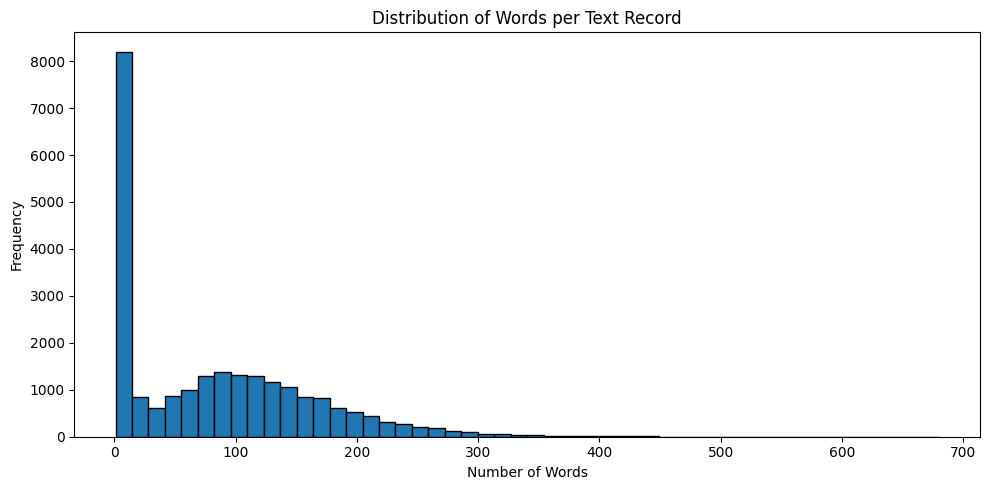

In [24]:
#Visualize text length distribution

plt.figure(figsize=(10, 5))

plt.hist(train_df["word_count"], bins=50, edgecolor="black")

plt.title("Distribution of Words per Text Record")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [25]:
#Calculate total word count

total_words = train_df["word_count"].sum()

print("Total words in training data:", total_words)
print("Average words per record:", round(train_df["word_count"].mean(), 2))

#Analyze the most frequent words

all_words = " ".join(train_df["clean_text"]).split()

word_frequency = Counter(all_words)

most_common_words = word_frequency.most_common(20)

frequency_df = pd.DataFrame(
    most_common_words,
    columns=["Word", "Frequency"]
)

frequency_df

Total words in training data: 1961025
Average words per record: 82.52


,Word,Frequency
0,the,130768
1,",",102612
2,.,76583
3,of,57032
4,and,50735
5,in,44989
6,to,39524
7,a,36324
8,was,21008
9,-,17147


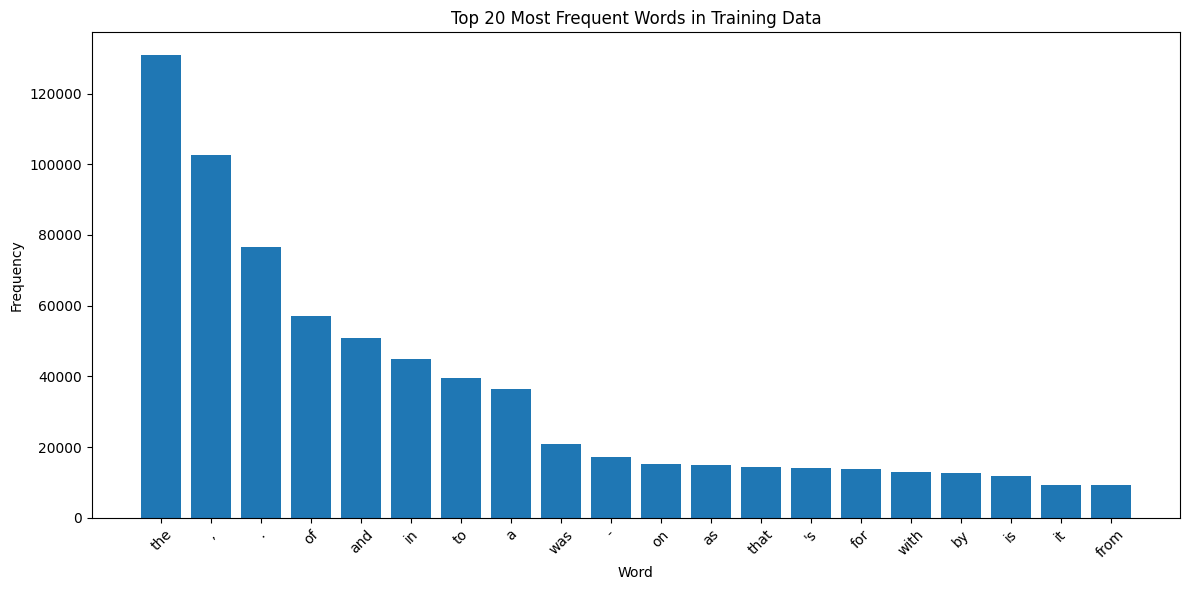

In [26]:
#Visualize the most frequent words

plt.figure(figsize=(12, 6))

plt.bar(
    frequency_df["Word"],
    frequency_df["Frequency"]
)

plt.title("Top 20 Most Frequent Words in Training Data")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [27]:
#Calculate vocabulary statistics

vocabulary = set(all_words)

print("Total word tokens:", len(all_words))
print("Unique words in training data:", len(vocabulary))
print("Vocabulary size:", len(vocabulary))

Total word tokens: 1961025
Unique words in training data: 65538
Vocabulary size: 65538


In [28]:
#Display sample cleaned text

for i, text in enumerate(train_df["clean_text"].head(5), start=1):
    print(f"Sample {i}:")
    print(text)
    print("-" * 80)

Sample 1:
valkyria chronicles iii
--------------------------------------------------------------------------------
Sample 2:
senj no valkyria 3 : unrecorded chronicles japanese : 3 , lit . valkyria of the battlefield 3 , commonly referred to as valkyria chronicles iii outside japan , is a tactical role - playing video game developed by sega and media.vision for the playstation portable . released in january 2011 in japan , it is the third game in the valkyria series . employing the same fusion of tactical and real - time gameplay as its predecessors , the story runs parallel to the first game and follows the nameless , a penal military unit serving the nation of gallia during the second europan war who perform secret black operations and are pitted against the imperial unit calamaty raven .
--------------------------------------------------------------------------------
Sample 3:
the game began development in 2010 , carrying over a large portion of the work done on valkyria chronicles 

In [29]:
#Final EDA summary

print("EDA SUMMARY")
print("=" * 40)
print("Training records:", len(train_df))
print("Total training word tokens:", len(all_words))
print("Unique training vocabulary:", len(vocabulary))
print("Average words per record:", round(train_df["word_count"].mean(), 2))
print("Maximum words in a record:", train_df["word_count"].max())
print("Minimum words in a record:", train_df["word_count"].min())

print("\nStep 3 completed: Exploratory Text Analysis.")

EDA SUMMARY
Training records: 23764
Total training word tokens: 1961025
Unique training vocabulary: 65538
Average words per record: 82.52
Maximum words in a record: 680
Minimum words in a record: 1

Step 3 completed: Exploratory Text Analysis.


In [30]:
#step 4 - Tokenization and Vocabulary Creation

In [31]:
#Import the required libraries

from collections import Counter
import re

print("Libraries imported successfully.")

Libraries imported successfully.


In [32]:
#Define the tokenizer
def tokenize_text(text):
    tokens = re.findall(
        r"[a-z0-9]+(?:['-][a-z0-9]+)*|[.,!?;:]",
        text.lower()
    )
    return tokens

In [33]:
#Tokenize the training data

train_tokens = [
    tokenize_text(text)
    for text in train_df["clean_text"]
]

print("Training tokenization completed.")
print("Number of text records:", len(train_tokens))
print("First record tokens:", train_tokens[0][:30])

Training tokenization completed.
Number of text records: 23764
First record tokens: ['valkyria', 'chronicles', 'iii']


In [34]:
#Tokenize validation and test data

validation_tokens = [
    tokenize_text(text)
    for text in validation_df["clean_text"]
]

test_tokens = [
    tokenize_text(text)
    for text in test_df["clean_text"]
]

print("Validation records tokenized:", len(validation_tokens))
print("Test records tokenized:", len(test_tokens))

Validation records tokenized: 2461
Test records tokenized: 2891


In [35]:
#Calculate word frequencies

token_counts = Counter(
    token
    for sentence in train_tokens
    for token in sentence
)

print("Total training tokens:", sum(token_counts.values()))
print("Unique training tokens:", len(token_counts))

Total training tokens: 1949485
Unique training tokens: 64831


In [36]:
#Create the vocabulary (frequent tokens only for faster softmax)
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
MIN_FREQUENCY = 2
MAX_VOCAB_SIZE = 8000
vocabulary_words = sorted(token_counts, key=lambda w: (-token_counts[w], w))
vocabulary_words = [w for w in vocabulary_words if token_counts[w] >= MIN_FREQUENCY][:MAX_VOCAB_SIZE-2]
vocabulary = [PAD_TOKEN, UNK_TOKEN] + vocabulary_words
word_to_id = {w:i for i,w in enumerate(vocabulary)}
id_to_word = {i:w for w,i in word_to_id.items()}
print("Vocabulary size:", len(vocabulary))
print("Training token coverage:", sum(token_counts[w] for w in vocabulary_words)/sum(token_counts.values()))

Vocabulary size: 8000
Training token coverage: 0.899618617224549


In [37]:
#Check vocabulary examples

print("First 20 vocabulary entries:")

for word, index in list(word_to_id.items())[:20]:
    print(f"{word}: {index}")

First 20 vocabulary entries:
<PAD>: 0
<UNK>: 1
the: 2
,: 3
.: 4
of: 5
and: 6
in: 7
to: 8
a: 9
was: 10
on: 11
s: 12
as: 13
that: 14
for: 15
with: 16
by: 17
is: 18
it: 19


In [38]:
#Convert tokens into numerical sequences

def tokens_to_ids(tokens):
    return [
        word_to_id.get(token, word_to_id[UNK_TOKEN])
        for token in tokens
    ]

sample_tokens = tokenize_text(
    "I would like to book a flight."
)

sample_ids = tokens_to_ids(sample_tokens)

print("Tokens:", sample_tokens)
print("Numerical IDs:", sample_ids)

Tokens: ['i', 'would', 'like', 'to', 'book', 'a', 'flight', '.']
Numerical IDs: [58, 59, 133, 8, 234, 9, 932, 4]


In [39]:
#Verify reverse mapping

reconstructed_tokens = [
    id_to_word[token_id]
    for token_id in sample_ids
]

print("Original tokens:", sample_tokens)
print("Reconstructed tokens:", reconstructed_tokens)

Original tokens: ['i', 'would', 'like', 'to', 'book', 'a', 'flight', '.']
Reconstructed tokens: ['i', 'would', 'like', 'to', 'book', 'a', 'flight', '.']


In [40]:
#Check unknown-word handling

unknown_sample = tokenize_text(
    "xyzabc unlistedword"
)

unknown_ids = tokens_to_ids(unknown_sample)

print("Input tokens:", unknown_sample)
print("Numerical IDs:", unknown_ids)
print("Unknown token ID:", word_to_id[UNK_TOKEN])

Input tokens: ['xyzabc', 'unlistedword']
Numerical IDs: [1, 1]
Unknown token ID: 1


In [41]:
#Final vocabulary summary

print("TOKENIZATION AND VOCABULARY SUMMARY")
print("=" * 45)
print("Training records:", len(train_tokens))
print("Validation records:", len(validation_tokens))
print("Test records:", len(test_tokens))
print("Total training tokens:", sum(token_counts.values()))
print("Unique tokens before filtering:", len(token_counts))
print("Final vocabulary size:", len(vocabulary))
print("Padding ID:", word_to_id[PAD_TOKEN])
print("Unknown ID:", word_to_id[UNK_TOKEN])

print("\nStep 4 completed successfully.")

TOKENIZATION AND VOCABULARY SUMMARY
Training records: 23764
Validation records: 2461
Test records: 2891
Total training tokens: 1949485
Unique tokens before filtering: 64831
Final vocabulary size: 8000
Padding ID: 0
Unknown ID: 1

Step 4 completed successfully.


In [42]:
#step 5 - Sequence Generation and Padding.

In [43]:
#Set sequence parameters
import random
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
SEQUENCE_LENGTH = 20
PAD_ID = word_to_id[PAD_TOKEN]
print("Context window:", SEQUENCE_LENGTH)
print("Vocabulary size:", len(vocabulary))

Context window: 20
Vocabulary size: 8000


In [44]:
#Create sequences from randomly sampled positions across the corpus
# Only known alphabetic target words are used; punctuation remains in the context.
def generate_sequences(tokenized_data, max_sequences=None, variable_context=False, seed=42):
    rng = np.random.default_rng(seed)
    encoded = [tokens_to_ids(tokens) for tokens in tokenized_data]
    eligible = []
    total_word_targets = 0
    for record, tokens in enumerate(tokenized_data):
        for i in range(1, len(tokens)):
            if any(ch.isalpha() for ch in tokens[i]):
                total_word_targets += 1
                if encoded[record][i] > 1:
                    eligible.append((record, i))
    size = len(eligible) if max_sequences is None else min(max_sequences, len(eligible))
    selected = rng.choice(len(eligible), size=size, replace=False)
    sequences = []
    for j in selected:
        record, target = eligible[j]
        ids = encoded[record]
        length = min(SEQUENCE_LENGTH, target)
        # Include short contexts in all splits, matching interactive use.
        if variable_context and rng.random() < 0.30:
            length = int(rng.integers(1, length+1))
        context = [PAD_ID]*(SEQUENCE_LENGTH-length) + ids[target-length:target]
        sequences.append((context, ids[target]))
    print(f"Known-word target coverage: {len(eligible)/max(1,total_word_targets):.2%}")
    return sequences

In [45]:
#Generate training, validation and test sequences
MAX_TRAIN_SEQUENCES = 120_000
MAX_VALIDATION_SEQUENCES = 5_000
MAX_TEST_SEQUENCES = 10_000
EPOCHS = 5
BATCH_SIZE = 128
train_sequences = generate_sequences(train_tokens, MAX_TRAIN_SEQUENCES, True, 42)
validation_sequences = generate_sequences(validation_tokens, MAX_VALIDATION_SEQUENCES, True, 43)
test_sequences = generate_sequences(test_tokens, MAX_TEST_SEQUENCES, True, 44)
print("Training sequences:", len(train_sequences))
print("Validation sequences:", len(validation_sequences))
print("Testing sequences:", len(test_sequences))

Known-word target coverage: 88.82%
Known-word target coverage: 87.22%
Known-word target coverage: 85.92%
Training sequences: 120000
Validation sequences: 5000
Testing sequences: 10000


In [46]:
#Separate inputs and target words

import numpy as np

X_train = np.array(
    [sequence[0] for sequence in train_sequences],
    dtype=np.int32
)
y_train = np.array(
    [sequence[1] for sequence in train_sequences],
    dtype=np.int32
)

X_validation = np.array(
    [sequence[0] for sequence in validation_sequences],
    dtype=np.int32
)
y_validation = np.array(
    [sequence[1] for sequence in validation_sequences],
    dtype=np.int32
)

X_test = np.array(
    [sequence[0] for sequence in test_sequences],
    dtype=np.int32
)
y_test = np.array(
    [sequence[1] for sequence in test_sequences],
    dtype=np.int32
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_validation:", X_validation.shape)
print("y_validation:", y_validation.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (120000, 20)
y_train: (120000,)
X_validation: (5000, 20)
y_validation: (5000,)
X_test: (10000, 20)
y_test: (10000,)


In [47]:
#Inspect a sample sequence

sample_index = 0

input_ids = X_train[sample_index]
target_id = y_train[sample_index]

input_words = [
    id_to_word[int(token_id)]
    for token_id in input_ids if token_id != PAD_ID
]

target_word = id_to_word[int(target_id)]

print("Input context:")
print(" ".join(input_words))

print("\nExpected next word:")
print(target_word)

Input context:
dubbed version <UNK> and <UNK> dubbed version <UNK> the warrior were released in more than 100 screens and 50

Expected next word:
screens


In [48]:
#Validate the generated sequences

assert X_train.ndim == 2
assert X_train.shape[1] == SEQUENCE_LENGTH
assert len(X_train) == len(y_train)

assert X_validation.shape[1] == SEQUENCE_LENGTH
assert len(X_validation) == len(y_validation)

assert X_test.shape[1] == SEQUENCE_LENGTH
assert len(X_test) == len(y_test)

assert len(X_train) > 0
assert len(X_validation) > 0
assert len(X_test) > 0

print("Sequence generation completed successfully!")

context_lengths = np.sum(X_train != PAD_ID, axis=1)
print("Short contexts:", np.sum(context_lengths < SEQUENCE_LENGTH))
print("Average context length:", context_lengths.mean())
assert np.all(context_lengths > 0)


Sequence generation completed successfully!
Short contexts: 48314
Average context length: 15.683416666666666


In [49]:
#Step 6- N-gram Language Model Development

In [50]:
#Import required libraries

from collections import defaultdict, Counter
import math
import numpy as np

In [51]:
#Prepare the training and evaluation data

ngram_train_tokens = [
    token
    for sentence in train_tokens
    for token in sentence
]

ngram_validation_tokens = [
    token
    for sentence in validation_tokens
    for token in sentence
]

ngram_test_tokens = [
    token
    for sentence in test_tokens
    for token in sentence
]

print("Training tokens:", len(ngram_train_tokens))
print("Validation tokens:", len(ngram_validation_tokens))
print("Testing tokens:", len(ngram_test_tokens))

Training tokens: 1949485
Validation tokens: 203904
Testing tokens: 229268


In [52]:
#Build a backoff trigram model (trigram -> bigram -> unigram)
NGRAM_ORDER = 3
ngram_counts = defaultdict(Counter)
bigram_counts = defaultdict(Counter)
unigram_counts = Counter()
valid_ids = {i for i,w in id_to_word.items() if i > 1 and any(ch.isalpha() for ch in w)}
for sentence in train_tokens:
    ids = tokens_to_ids(sentence)
    for i in range(1,len(ids)):
        target = ids[i]
        if target not in valid_ids:
            continue
        unigram_counts[target] += 1
        bigram_counts[ids[i-1]][target] += 1
        if i >= 2:
            ngram_counts[tuple(ids[i-2:i])][target] += 1
print("Trigram contexts learned:", len(ngram_counts))
UNIGRAM_TOTAL = sum(unigram_counts.values())
UNIGRAM_TOP = unigram_counts.most_common(20)

Trigram contexts learned: 318527


In [53]:
#Rank predictions using backoff for unseen or sparse contexts
from functools import lru_cache
@lru_cache(maxsize=50000)
def ngram_rank(context, top_k=5):
    scores = {}
    for counts, weight in [(ngram_counts.get(context), 1.0), (bigram_counts.get(context[-1]) if context else None, 0.25)]:
        if counts:
            total = sum(counts.values())
            for i,c in counts.items():
                scores[i] = scores.get(i,0) + weight*c/total
    total = UNIGRAM_TOTAL
    for i,c in UNIGRAM_TOP[:top_k]:
        scores.setdefault(i,0)
    for i in scores:
        scores[i] += 0.05*unigram_counts[i]/max(1,total)
    return sorted(scores.items(), key=lambda x:(-x[1],x[0]))[:top_k]

def predict_next_word_ngram(context_words, top_k=5):
    ids = tokens_to_ids(tokenize_text(clean_text(context_words)))
    return [(id_to_word[i], score) for i,score in ngram_rank(tuple(ids[-2:]),top_k)]

In [54]:
#Test next-word prediction

test_context = "the united"

predictions = predict_next_word_ngram(test_context, top_k=5)

print("Input context:", test_context)
print("\nTop next-word predictions:")

for word, score in predictions:
    print(f"{word}: {score:.6f}")

Input context: the united

Top next-word predictions:
states: 0.934332
kingdom: 0.216349
nations: 0.055738
in: 0.006957
arab: 0.005673


In [55]:
test_context = "one of"

predictions = predict_next_word_ngram(test_context, top_k=5)

print("Input context:", test_context)

for word, score in predictions:
    print(f"{word}: {score:.6f}")

Input context: one of
the: 0.742317
his: 0.058635
their: 0.022745
these: 0.021834
a: 0.021205


In [56]:
#Evaluate trigram on the same validation positions as neural models

def evaluate_ngram_metrics(X, y, top_k=5):
    top1 = top5 = 0
    for context, target in zip(X, y):
        ids = [int(i) for i in context if i != PAD_ID]
        ranked = [i for i,p in ngram_rank(tuple(ids[-2:]), top_k)]
        top1 += bool(ranked and ranked[0] == target)
        top5 += int(target in ranked)
    return {"Top-1 Accuracy": top1/len(y), "Top-5 Accuracy": top5/len(y), "Examples": len(y)}

print("Trigram validation:", evaluate_ngram_metrics(X_validation, y_validation))

Trigram validation: {'Top-1 Accuracy': 0.1926, 'Top-5 Accuracy': 0.3572, 'Examples': 5000}


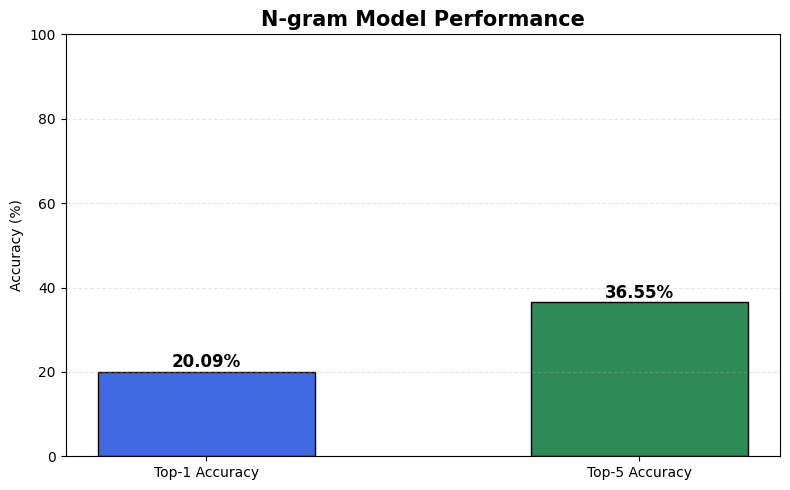

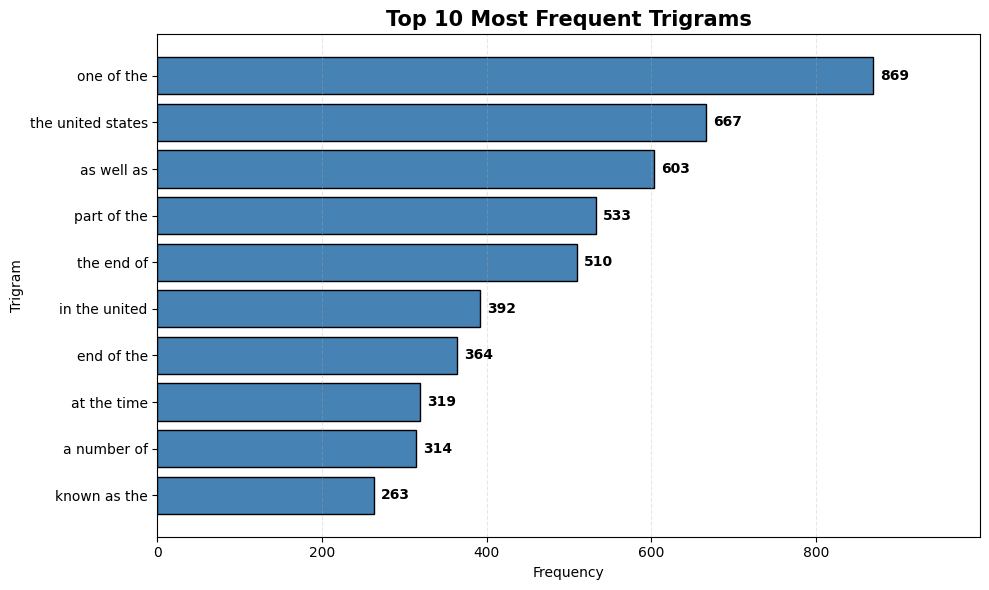

N-GRAM MODEL PERFORMANCE SUMMARY
Model Type       : Statistical Language Model
N-gram Order     : 3 (Trigram)
Context Window   : 2 Tokens
Vocabulary Size  : 8000
Top-1 Accuracy   : 20.09%
Top-5 Accuracy   : 36.55%

Graphs saved successfully:
1. ngram_performance.png
2. ngram_trigrams.png

Saved Location: C:\Users\harsh\next word prediction


In [108]:
# ============================================================
# STEP 9.1: N-GRAM MODEL PERFORMANCE VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\harsh\next word prediction")

# ------------------------------------------------------------
# 1. N-gram Accuracy Graph
# ------------------------------------------------------------

ngram_result = comparison_results[
    comparison_results["Model"] == "N-gram"
].iloc[0]

metrics = ["Top-1 Accuracy", "Top-5 Accuracy"]

accuracy = [
    ngram_result["Top-1 Accuracy (%)"],
    ngram_result["Top-5 Accuracy (%)"]
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    metrics,
    accuracy,
    color=["royalblue", "seagreen"],
    width=0.5,
    edgecolor="black"
)

for bar, value in zip(bars, accuracy):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.title(
    "N-gram Model Performance",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "ngram_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 2. Top 10 Most Frequent Trigrams
# ------------------------------------------------------------

trigram_frequency = Counter()

for context, next_words in ngram_counts.items():

    for next_id, count in next_words.items():

        trigram_ids = tuple(context) + (next_id,)

        words = [id_to_word[i] for i in trigram_ids]

        # Exclude punctuation and special tokens
        if all(word.isalpha() for word in words):

            trigram = " ".join(words)

            trigram_frequency[trigram] += count

top_trigrams = trigram_frequency.most_common(10)

phrases = [item[0] for item in top_trigrams]

frequencies = [item[1] for item in top_trigrams]

plt.figure(figsize=(10, 6))

bars = plt.barh(
    phrases,
    frequencies,
    color="steelblue",
    edgecolor="black"
)

plt.gca().invert_yaxis()

for bar, value in zip(bars, frequencies):

    plt.text(
        value + max(frequencies) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        str(value),
        va="center",
        fontweight="bold"
    )

plt.title(
    "Top 10 Most Frequent Trigrams",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Frequency")
plt.ylabel("Trigram")

plt.xlim(0, max(frequencies) * 1.15)

plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "ngram_trigrams.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 3. Performance Summary
# ------------------------------------------------------------

print("=" * 60)
print("N-GRAM MODEL PERFORMANCE SUMMARY")
print("=" * 60)

print("Model Type       : Statistical Language Model")
print("N-gram Order     : 3 (Trigram)")
print("Context Window   : 2 Tokens")
print("Vocabulary Size  :", len(word_to_id))

print(f"Top-1 Accuracy   : {accuracy[0]:.2f}%")
print(f"Top-5 Accuracy   : {accuracy[1]:.2f}%")

print("\nGraphs saved successfully:")
print("1. ngram_performance.png")
print("2. ngram_trigrams.png")

print("\nSaved Location:", PROJECT_DIR)

print("=" * 60)

In [57]:
#step 7 - LSTM Model Development

In [58]:
# Install TensorFlow if needed
# %pip install tensorflow

In [59]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

print("TensorFlow version:", tf.__version__)
print("LSTM libraries imported successfully.")
tf.keras.utils.set_random_seed(SEED)

TensorFlow version: 2.21.0
LSTM libraries imported successfully.


In [60]:
#Define the LSTM architecture
EMBEDDING_DIM = 48
LSTM_UNITS = 64
VOCAB_SIZE = len(vocabulary)

lstm_model = Sequential([
    tf.keras.Input(shape=(SEQUENCE_LENGTH,), dtype="int32"),
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),
    LSTM(LSTM_UNITS),
    Dropout(0.2),
    Dense(VOCAB_SIZE, activation="softmax")
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 20, 48)              │         384,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 64)                  │          28,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 8000)                │         520,000 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 932,928 (3.56 MB)

 Trainable params: 932,928 (3.56 MB)

 Non-trainable params: 0 (0.00 B)

In [82]:
# Train the LSTM model

from tensorflow.keras.callbacks import EarlyStopping
import time

start_time = time.time()

early_stopping_lstm = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_lstm = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=10,
    batch_size=128,
    shuffle=True,
    callbacks=[early_stopping_lstm],
    verbose=1
)

lstm_training_time = time.time() - start_time

print(
    f"LSTM Training Time: "
    f"{lstm_training_time / 60:.2f} minutes"
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 81s 86ms/step - accuracy: 0.1459 - loss: 6.0017 - val_accuracy: 0.1434 - val_loss: 6.2038
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 74s 79ms/step - accuracy: 0.1520 - loss: 5.9017 - val_accuracy: 0.1476 - val_loss: 6.1751
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 79ms/step - accuracy: 0.1578 - loss: 5.8062 - val_accuracy: 0.1514 - val_loss: 6.1584
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 74s 79ms/step - accuracy: 0.1630 - loss: 5.7196 - val_accuracy: 0.1548 - val_loss: 6.1542
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 75s 79ms/step - accuracy: 0.1678 - loss: 5.6430 - val_accuracy: 0.1570 - val_loss: 6.1600
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 75s 80ms/step - accuracy: 0.1719 - loss: 5.5709 - val_accuracy: 0.1594 - val_loss: 6.1709
LSTM Training Time: 7.82 minutes


In [83]:
#Evaluate the LSTM model

lstm_loss, lstm_accuracy = lstm_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"LSTM Test Loss: {lstm_loss:.4f}")
print(f"LSTM Test Accuracy: {lstm_accuracy:.4f}")
print(f"LSTM Test Accuracy: {lstm_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.1587 - loss: 6.0239
LSTM Test Loss: 6.0239
LSTM Test Accuracy: 0.1587
LSTM Test Accuracy: 15.87%


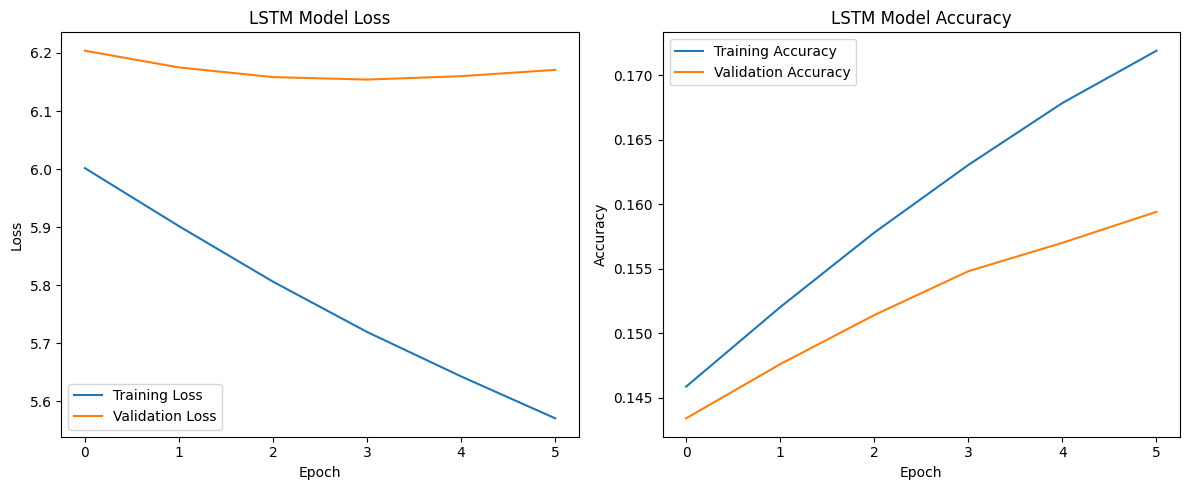

In [84]:
#Plot training performance

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_lstm.history["loss"], label="Training Loss")
plt.plot(history_lstm.history["val_loss"], label="Validation Loss")
plt.title("LSTM Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_lstm.history["accuracy"], label="Training Accuracy")
plt.plot(history_lstm.history["val_accuracy"], label="Validation Accuracy")
plt.title("LSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [85]:
# LSTM retained in memory for comparison; no intermediate export needed.
print("LSTM training and evaluation complete.")

LSTM training and evaluation complete.


In [86]:
#Step 8- GRU Model Development

In [87]:
#Import GRU layer

from tensorflow.keras.layers import GRU

print("GRU layer imported successfully!")

GRU layer imported successfully!


In [88]:
#Build the GRU model

GRU_UNITS = 64
EMBEDDING_DIM = 48
VOCAB_SIZE = len(vocabulary)

gru_model = Sequential([
    tf.keras.Input(shape=(SEQUENCE_LENGTH,), dtype="int32"),
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),
    GRU(GRU_UNITS),
    Dropout(0.2),
    Dense(VOCAB_SIZE, activation="softmax")
])

gru_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)              │ (None, 20, 48)              │         384,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_1 (GRU)                          │ (None, 64)                  │          21,888 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 8000)                │         520,000 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 925,888 (3.53 MB)

 Trainable params: 925,888 (3.53 MB)

 Non-trainable params: 0 (0.00 B)

In [89]:
# Train the GRU model

from tensorflow.keras.callbacks import EarlyStopping
import time

start_time = time.time()

early_stopping_gru = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_gru = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=10,
    batch_size=128,
    shuffle=True,
    callbacks=[early_stopping_gru],
    verbose=1
)

gru_training_time = time.time() - start_time

print(
    f"GRU Training Time: "
    f"{gru_training_time / 60:.2f} minutes"
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 92s 90ms/step - accuracy: 0.0975 - loss: 6.8873 - val_accuracy: 0.1294 - val_loss: 6.4652
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 78s 83ms/step - accuracy: 0.1270 - loss: 6.3319 - val_accuracy: 0.1364 - val_loss: 6.2838
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 74s 79ms/step - accuracy: 0.1417 - loss: 6.1288 - val_accuracy: 0.1492 - val_loss: 6.1871
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 83s 80ms/step - accuracy: 0.1550 - loss: 5.9630 - val_accuracy: 0.1584 - val_loss: 6.1128
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 61s 58ms/step - accuracy: 0.1655 - loss: 5.8126 - val_accuracy: 0.1640 - val_loss: 6.0695
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 34s 36ms/step - accuracy: 0.1740 - loss: 5.6825 - val_accuracy: 0.1668 - val_loss: 6.0520
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 35s 37ms/step - accuracy: 0.1804 - loss: 5.5679 - val_accuracy: 0.1700 - val_loss: 6.0482
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 37ms/step - accuracy: 0.1855 - loss: 5.4611 - 

In [90]:
#Evaluate the GRU model

gru_loss, gru_accuracy = gru_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"GRU Test Loss: {gru_loss:.4f}")
print(f"GRU Test Accuracy: {gru_accuracy:.4f}")
print(f"GRU Test Accuracy: {gru_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.1679 - loss: 5.9298
GRU Test Loss: 5.9298
GRU Test Accuracy: 0.1679
GRU Test Accuracy: 16.79%


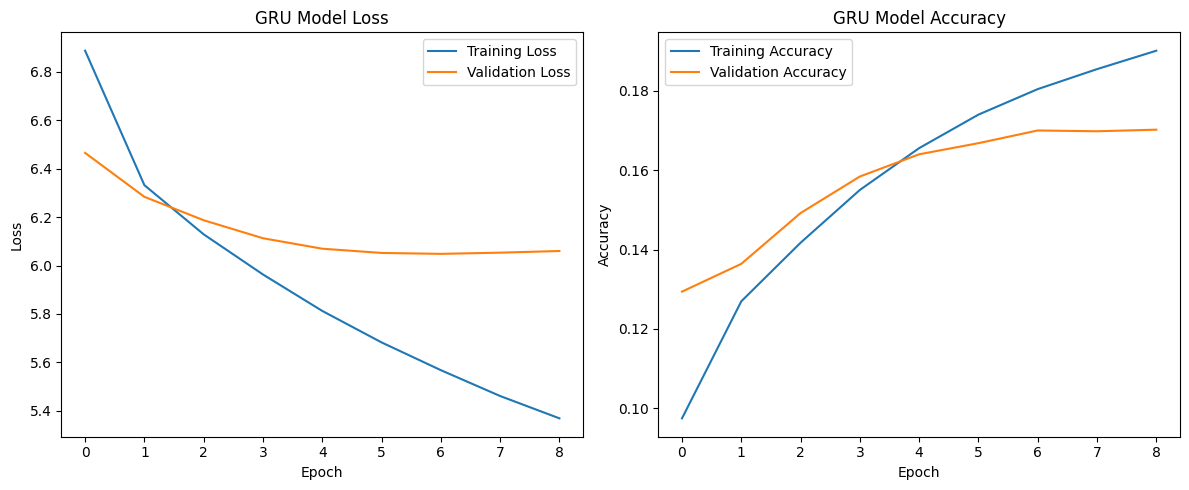

In [91]:
#Plot training performance

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_gru.history["loss"], label="Training Loss")
plt.plot(history_gru.history["val_loss"], label="Validation Loss")
plt.title("GRU Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_gru.history["accuracy"], label="Training Accuracy")
plt.plot(history_gru.history["val_accuracy"], label="Validation Accuracy")
plt.title("GRU Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [92]:
# GRU will be exported with its matching vocabulary in Step 10.
print("GRU training and evaluation complete.")

GRU training and evaluation complete.


In [93]:
#Step 9- Model Evaluation and Performance Comparison

In [94]:
#Create the model comparison table

model_comparison = pd.DataFrame({
    "Model": ["N-gram", "LSTM", "GRU"],
    "Test Accuracy": [
        np.nan,
        lstm_accuracy,
        gru_accuracy
    ],
    "Test Loss": [
        np.nan,
        lstm_loss,
        gru_loss
    ]
})

model_comparison

,Model,Test Accuracy,Test Loss
0,N-gram,NaN,NaN
1,LSTM,0.1587,6.023894
2,GRU,0.1679,5.929808


In [95]:
#Evaluate top-k word suggestions in small batches (same targets for all models)
def evaluate_neural_model(model, X, y, batch_size=128):
    top1 = top5 = 0
    allowed = np.array(sorted(valid_ids), dtype=np.int32)
    k = min(5, len(allowed))
    for start in range(0,len(y),batch_size):
        actual = y[start:start+batch_size]
        probabilities = model(X[start:start+batch_size], training=False).numpy()[:,allowed]
        top1 += np.sum(allowed[np.argmax(probabilities,axis=1)] == actual)
        ranked = allowed[np.argpartition(probabilities,-k,axis=1)[:,-k:]]
        top5 += np.sum(np.any(ranked == actual[:,None],axis=1))
    return {"Top-1 Accuracy":float(top1/len(y)), "Top-5 Accuracy":float(top5/len(y))}
lstm_metrics = evaluate_neural_model(lstm_model,X_test,y_test)
gru_metrics = evaluate_neural_model(gru_model,X_test,y_test)
print("LSTM:",lstm_metrics)
print("GRU:",gru_metrics)

LSTM: {'Top-1 Accuracy': 0.1587, 'Top-5 Accuracy': 0.2983}
GRU: {'Top-1 Accuracy': 0.1679, 'Top-5 Accuracy': 0.3119}


In [96]:
#Calculate N-gram metrics on identical test positions
ngram_metrics = evaluate_ngram_metrics(X_test, y_test)
print("N-gram metrics:", ngram_metrics)

N-gram metrics: {'Top-1 Accuracy': 0.2009, 'Top-5 Accuracy': 0.3655, 'Examples': 10000}


In [97]:
# Build the final comparison table

comparison_results = pd.DataFrame([
    {
        "Model": "N-gram",
        "Top-1 Accuracy": ngram_metrics["Top-1 Accuracy"],
        "Top-5 Accuracy": ngram_metrics["Top-5 Accuracy"],
        "Test Loss": np.nan
    },
    {
        "Model": "LSTM",
        "Top-1 Accuracy": lstm_metrics["Top-1 Accuracy"],
        "Top-5 Accuracy": lstm_metrics["Top-5 Accuracy"],
        "Test Loss": lstm_loss
    },
    {
        "Model": "GRU",
        "Top-1 Accuracy": gru_metrics["Top-1 Accuracy"],
        "Top-5 Accuracy": gru_metrics["Top-5 Accuracy"],
        "Test Loss": gru_loss
    }
])

comparison_results["Top-1 Accuracy (%)"] = (
    comparison_results["Top-1 Accuracy"] * 100
)
comparison_results["Top-5 Accuracy (%)"] = (
    comparison_results["Top-5 Accuracy"] * 100
)

comparison_results.round(4)

,Model,Top-1 Accuracy,Top-5 Accuracy,Test Loss,Top-1 Accuracy (%),Top-5 Accuracy (%)
0,N-gram,0.2009,0.3655,NaN,20.09,36.55
1,LSTM,0.1587,0.2983,6.0239,15.87,29.83
2,GRU,0.1679,0.3119,5.9298,16.79,31.19


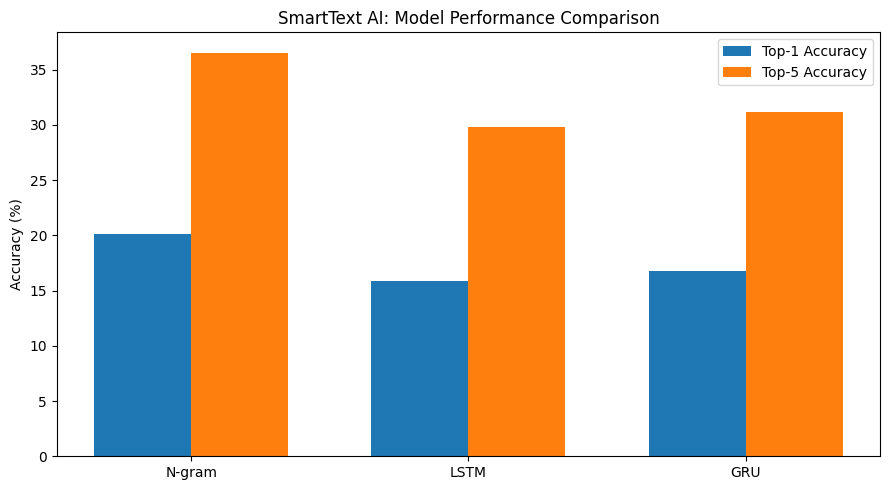

In [98]:
# Visualize the accuracy comparison

plt.figure(figsize=(9, 5))

x = np.arange(len(comparison_results))
width = 0.35

plt.bar(
    x - width / 2,
    comparison_results["Top-1 Accuracy (%)"],
    width,
    label="Top-1 Accuracy"
)

plt.bar(
    x + width / 2,
    comparison_results["Top-5 Accuracy (%)"],
    width,
    label="Top-5 Accuracy"
)

plt.xticks(x, comparison_results["Model"])
plt.ylabel("Accuracy (%)")
plt.title("SmartText AI: Model Performance Comparison")
plt.legend()
plt.tight_layout()
plt.show()

In [99]:
# Identify the best model by Top-5 accuracy

best_model_row = comparison_results.loc[
    comparison_results["Top-5 Accuracy"].idxmax()
]

print("Best model based on Top-5 accuracy:", best_model_row["Model"])
print(
    "Top-5 accuracy:",
    f'{best_model_row["Top-5 Accuracy (%)"]:.2f}%'
)

Best model based on Top-5 accuracy: N-gram
Top-5 accuracy: 36.55%


In [100]:
#Step 10- Next-Word Prediction and Streamlit Application Development

In [104]:
# ============================================================
# STEP 10: SAVE ALL TRAINED MODELS AND VERIFY PROJECT FILES
# SmartText AI - Intelligent Next Word Prediction System
# ============================================================

import os
import json
import pickle
import numpy as np
import pandas as pd
import tensorflow as tf

from pathlib import Path

# ------------------------------------------------------------
# 1. Set project directory
# ------------------------------------------------------------

PROJECT_DIR = Path(r"C:\Users\harsh\next word prediction")

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

os.chdir(PROJECT_DIR)

print("=" * 65)
print("SMARTTEXT AI - MODEL EXPORT")
print("=" * 65)

print("\nProject Directory:", PROJECT_DIR)


# ------------------------------------------------------------
# 2. Identify the best-performing model
# ------------------------------------------------------------

best_model_row = comparison_results.loc[
    comparison_results["Top-5 Accuracy (%)"].idxmax()
]

BEST_MODEL = str(best_model_row["Model"])

print("\nBest Performing Model:", BEST_MODEL)

print(
    "Top-5 Accuracy:",
    f'{best_model_row["Top-5 Accuracy (%)"]:.2f}%'
)


# ------------------------------------------------------------
# 3. Test N-gram, LSTM and GRU predictions
# ------------------------------------------------------------

test_sentences = [
    "during the second world",
    "the united",
    "at the end of the",
    "the film was released in",
    "a large number of"
]

print("\n" + "=" * 65)
print("SAMPLE NEXT WORD PREDICTIONS")
print("=" * 65)

for text in test_sentences:

    print("\nInput:", text)

    # N-gram predictions

    ngram_predictions = predict_next_word_ngram(
        text,
        top_k=5
    )

    print("\nN-gram Predictions:")

    for word, score in ngram_predictions:
        print(f"  {word:<15} Score: {score:.4f}")

    # Prepare input for neural network models

    tokens = tokenize_text(clean_text(text))

    ids = tokens_to_ids(tokens)[-SEQUENCE_LENGTH:]

    input_ids = np.zeros(
        (1, SEQUENCE_LENGTH),
        dtype=np.int32
    )

    if ids:
        input_ids[0, -len(ids):] = ids

    # LSTM and GRU predictions

    for model_name, model in [
        ("LSTM", lstm_model),
        ("GRU", gru_model)
    ]:

        probabilities = model(
            input_ids,
            training=False
        ).numpy()[0]

        ranked_ids = sorted(
            valid_ids,
            key=lambda i: (-probabilities[i], i)
        )[:5]

        print(f"\n{model_name} Predictions:")

        for i in ranked_ids:

            print(
                f"  {id_to_word[i]:<15}"
                f"Probability: {probabilities[i] * 100:.2f}%"
            )

    print("-" * 65)


# ------------------------------------------------------------
# 4. Save trained N-gram model
# ------------------------------------------------------------

NGRAM_PATH = PROJECT_DIR / "smarttext_ngram.pkl"

ngram_model = {
    "ngram_order": NGRAM_ORDER,
    "ngram_counts": dict(ngram_counts),
    "bigram_counts": dict(bigram_counts),
    "unigram_counts": unigram_counts,
    "unigram_total": UNIGRAM_TOTAL,
    "unigram_top": UNIGRAM_TOP
}

with open(NGRAM_PATH, "wb") as file:

    pickle.dump(
        ngram_model,
        file,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print("\nN-gram model saved successfully!")


# ------------------------------------------------------------
# 5. Save trained LSTM and GRU models
# ------------------------------------------------------------

LSTM_PATH = PROJECT_DIR / "smarttext_lstm.keras"

GRU_PATH = PROJECT_DIR / "smarttext_gru.keras"

lstm_model.save(LSTM_PATH)

print("LSTM model saved successfully!")

gru_model.save(GRU_PATH)

print("GRU model saved successfully!")


# ------------------------------------------------------------
# 6. Save vocabulary
# ------------------------------------------------------------

VOCAB_PATH = PROJECT_DIR / "smarttext_vocabulary.json"

with open(VOCAB_PATH, "w", encoding="utf-8") as file:

    json.dump(
        word_to_id,
        file,
        ensure_ascii=False,
        indent=2
    )

print("Vocabulary saved successfully!")

print("Vocabulary Size:", len(word_to_id))


# ------------------------------------------------------------
# 7. Save model configuration and performance
# ------------------------------------------------------------

CONFIG_PATH = PROJECT_DIR / "smarttext_config.json"

model_config = {
    "project_name": "SmartText AI",
    "dataset": "WikiText-2",
    "vocabulary_size": len(word_to_id),
    "sequence_length": SEQUENCE_LENGTH,
    "padding_id": 0,
    "unknown_id": 1,
    "embedding_dimension": 48,
    "hidden_units": 64,
    "dropout": 0.2,
    "maximum_epochs": 10,
    "default_model": BEST_MODEL,
    "models": ["N-gram", "LSTM", "GRU"],
    "model_performance": {}
}

for _, row in comparison_results.iterrows():

    model_config["model_performance"][row["Model"]] = {

        "top_1_accuracy": float(
            row["Top-1 Accuracy (%)"]
        ),

        "top_5_accuracy": float(
            row["Top-5 Accuracy (%)"]
        ),

        "test_loss": (
            None
            if pd.isna(row["Test Loss"])
            else float(row["Test Loss"])
        )
    }

with open(CONFIG_PATH, "w", encoding="utf-8") as file:

    json.dump(
        model_config,
        file,
        indent=4
    )

print("Model configuration saved successfully!")


# ------------------------------------------------------------
# 8. Verify vocabulary compatibility
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("MODEL VERIFICATION")
print("=" * 65)

assert set(word_to_id.values()) == set(
    range(len(word_to_id))
), "Invalid vocabulary mapping!"

assert lstm_model.output_shape[-1] == len(word_to_id), \
    "LSTM vocabulary size mismatch!"

assert gru_model.output_shape[-1] == len(word_to_id), \
    "GRU vocabulary size mismatch!"

with open(VOCAB_PATH, "r", encoding="utf-8") as file:

    saved_vocabulary = json.load(file)

assert saved_vocabulary == word_to_id, \
    "Saved vocabulary mismatch!"

print("\nVocabulary compatibility verified!")


# ------------------------------------------------------------
# 9. Verify saved N-gram model
# ------------------------------------------------------------

with open(NGRAM_PATH, "rb") as file:

    saved_ngram = pickle.load(file)

assert saved_ngram["ngram_counts"] == ngram_counts

assert saved_ngram["bigram_counts"] == bigram_counts

assert saved_ngram["unigram_counts"] == unigram_counts

assert saved_ngram["unigram_total"] == UNIGRAM_TOTAL

assert saved_ngram["unigram_top"] == UNIGRAM_TOP

print("N-gram model verification passed!")


# ------------------------------------------------------------
# 10. Verify saved LSTM and GRU models
# ------------------------------------------------------------

for model_name, original_model, model_path in [

    ("LSTM", lstm_model, LSTM_PATH),

    ("GRU", gru_model, GRU_PATH)

]:

    loaded_model = tf.keras.models.load_model(
        model_path,
        compile=False
    )

    original_predictions = original_model(
        X_test[:8],
        training=False
    ).numpy()

    loaded_predictions = loaded_model(
        X_test[:8],
        training=False
    ).numpy()

    np.testing.assert_allclose(
        original_predictions,
        loaded_predictions,
        rtol=1e-5,
        atol=1e-6
    )

    print(f"{model_name} model verification passed!")

    del loaded_model


# ------------------------------------------------------------
# 11. Verify all exported files
# ------------------------------------------------------------

required_files = [
    NGRAM_PATH,
    LSTM_PATH,
    GRU_PATH,
    VOCAB_PATH,
    CONFIG_PATH
]

print("\n" + "=" * 65)
print("EXPORTED PROJECT FILES")
print("=" * 65)

for file in required_files:

    assert file.exists(), f"Missing file: {file.name}"

    file_size = file.stat().st_size / (1024 ** 2)

    print(
        f"{file.name:<35}"
        f"{file_size:>8.2f} MB"
    )


# ------------------------------------------------------------
# 12. Display final model comparison
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL MODEL PERFORMANCE")
print("=" * 65)

display(
    comparison_results[
        [
            "Model",
            "Top-1 Accuracy (%)",
            "Top-5 Accuracy (%)",
            "Test Loss"
        ]
    ].round(4)
)


# ------------------------------------------------------------
# 13. Check Streamlit application
# ------------------------------------------------------------

APP_PATH = PROJECT_DIR / "app.py"

if APP_PATH.exists():

    print("\nStreamlit application found:", APP_PATH)

else:

    print("\nStreamlit application needs to be created.")


# ------------------------------------------------------------
# 14. Final project summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SMARTTEXT AI - PROJECT SUMMARY")
print("=" * 65)

print("Dataset              : WikiText-2")
print("Models               : N-gram, LSTM, GRU")
print("Vocabulary Size      :", len(word_to_id))
print("Sequence Length      :", SEQUENCE_LENGTH)
print("Maximum Epochs       : 10")
print("LSTM Actual Epochs   :", len(history_lstm.history["loss"]))
print("GRU Actual Epochs    :", len(history_gru.history["loss"]))
print("Best Model           :", BEST_MODEL)

print(
    "Best Top-1 Accuracy  :",
    f'{best_model_row["Top-1 Accuracy (%)"]:.2f}%'
)

print(
    "Best Top-5 Accuracy  :",
    f'{best_model_row["Top-5 Accuracy (%)"]:.2f}%'
)

print("Model Export Status  : Successful")
print("Model Verification   : Successful")

print("\nAll trained models have been saved successfully!")

print("SmartText AI is ready for Streamlit integration.")



print("=" * 65)

SMARTTEXT AI - MODEL EXPORT

Project Directory: C:\Users\harsh\next word prediction

Best Performing Model: N-gram
Top-5 Accuracy: 36.55%

SAMPLE NEXT WORD PREDICTIONS

Input: during the second world

N-gram Predictions:
  war             Score: 1.0288
  wars            Score: 0.0438
  cup             Score: 0.0235
  tour            Score: 0.0164
  s               Score: 0.0135

LSTM Predictions:
  of             Probability: 4.25%
  and            Probability: 3.27%
  in             Probability: 2.44%
  season         Probability: 2.21%
  year           Probability: 1.96%

GRU Predictions:
  war            Probability: 9.46%
  season         Probability: 3.47%
  to             Probability: 3.26%
  of             Probability: 2.79%
  year           Probability: 1.93%
-----------------------------------------------------------------

Input: the united

N-gram Predictions:
  states          Score: 0.9343
  kingdom         Score: 0.2163
  nations         Score: 0.0557
  in              Sc

,Model,Top-1 Accuracy (%),Top-5 Accuracy (%),Test Loss
0,N-gram,20.09,36.55,NaN
1,LSTM,15.87,29.83,6.0239
2,GRU,16.79,31.19,5.9298



Streamlit application found: C:\Users\harsh\next word prediction\app.py

SMARTTEXT AI - PROJECT SUMMARY
Dataset              : WikiText-2
Models               : N-gram, LSTM, GRU
Vocabulary Size      : 8000
Sequence Length      : 20
Maximum Epochs       : 10
LSTM Actual Epochs   : 6
GRU Actual Epochs    : 9
Best Model           : N-gram
Best Top-1 Accuracy  : 20.09%
Best Top-5 Accuracy  : 36.55%
Model Export Status  : Successful
Model Verification   : Successful

All trained models have been saved successfully!
SmartText AI is ready for Streamlit integration.


In [106]:
import os
import sys
import subprocess
import webbrowser
import time

# Set project directory
PROJECT_DIR = r"C:\Users\harsh\next word prediction"

os.chdir(PROJECT_DIR)

# Launch Streamlit application
process = subprocess.Popen([
    sys.executable,
    "-m",
    "streamlit",
    "run",
    "app.py",
    "--server.port", "8502",
    "--server.headless", "true"
])

# Wait for Streamlit to start
time.sleep(5)

# Localhost URL
url = "http://localhost:8502"

print("SmartText AI launched!")
print("Local URL:", url)

# Open application in browser
webbrowser.open(url)

SmartText AI launched!
Local URL: http://localhost:8502


True